<a href="https://colab.research.google.com/github/Juanpatula2361/Taller-Redes-Neuronales-II/blob/main/notebooks/03_mlp_backpropagation_numpy.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# Notebook 03 — Perceptrón multicapa (MLP) modular con backpropagation (NumPy)

**Curso:** Deep Learning – Conceptos · Especialización en Inteligencia Artificial · Universidad de Cundinamarca
**Semana 2:** rediseño del MLP de Redes Neuronales I para que funcione con **cualquier dataset binario**.

Diseño modular (el mismo patrón que usan Keras y PyTorch internamente):

- Cada **capa** es un objeto con `forward(x)` y `backward(grad)`.
- `Densa` guarda sus parámetros $W, b$ y sus gradientes $dW, db$.
- `ReLU` y `Sigmoide` son capas sin parámetros.
- `MLP` encadena las capas a partir de una lista de arquitectura, p. ej. `[2, 32, 16, 1]`.
- El entrenamiento usa **mini-batch gradient descent** y se valida con **gradient checking** numérico.

Se aplica a dos datasets: `make_moons` (sintético 2D) y **Breast Cancer Wisconsin** (real, 30 variables).

[![Open In Colab](https://colab.research.google.com/assets/colab-badge.svg)](https://colab.research.google.com/github/Juanpatula2361/Taller-Redes-Neuronales-II/blob/main/notebooks/03_mlp_backpropagation_numpy.ipynb)

In [1]:
# ============================================================
# 0. Importaciones y configuración
# ============================================================
import os
import numpy as np
import matplotlib.pyplot as plt
from sklearn.datasets import make_moons, load_breast_cancer
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
from sklearn.metrics import confusion_matrix, classification_report, ConfusionMatrixDisplay

SEED = 42
np.random.seed(SEED)
FIG_DIR = "figuras"
os.makedirs(FIG_DIR, exist_ok=True)

## 1. Capas del modelo

Para una capa densa $Z = XW + b$, dado el gradiente que llega desde arriba $\delta = \partial\mathcal{L}/\partial Z$:

$$ \frac{\partial\mathcal{L}}{\partial W} = X^\top\delta, \qquad \frac{\partial\mathcal{L}}{\partial b} = \textstyle\sum_i \delta_i, \qquad \frac{\partial\mathcal{L}}{\partial X} = \delta\,W^\top $$

Para una activación $A = g(Z)$: $\;\partial\mathcal{L}/\partial Z = \partial\mathcal{L}/\partial A \odot g'(Z)$.
Backpropagation consiste en llamar `backward` de la última capa a la primera, pasando el gradiente de mano en mano.

In [2]:
# ============================================================
# 1. Capas: Densa, ReLU, Sigmoide y pérdida BCE
# ============================================================
class Densa:
    """Capa totalmente conectada: Z = X W + b."""

    def __init__(self, n_entrada, n_salida, init="he", rng=None):
        rng = rng or np.random.default_rng(SEED)
        escala = np.sqrt(2.0 / n_entrada) if init == "he" else np.sqrt(1.0 / n_entrada)
        self.W = rng.normal(0.0, escala, size=(n_entrada, n_salida))
        self.b = np.zeros((1, n_salida))
        self.dW = np.zeros_like(self.W)
        self.db = np.zeros_like(self.b)

    def forward(self, X):
        self.X = X                          # se guarda la entrada para el backward
        return X @ self.W + self.b

    def backward(self, grad):
        self.dW = self.X.T @ grad
        self.db = grad.sum(axis=0, keepdims=True)
        return grad @ self.W.T              # gradiente hacia la capa anterior

    def parametros(self):
        return [(self.W, self.dW), (self.b, self.db)]


class ReLU:
    def forward(self, Z):
        self.mascara = Z > 0
        return Z * self.mascara

    def backward(self, grad):
        return grad * self.mascara          # g'(z) = 1 si z > 0, 0 en otro caso

    def parametros(self):
        return []


class Sigmoide:
    def forward(self, Z):
        self.A = 1.0 / (1.0 + np.exp(-np.clip(Z, -500, 500)))
        return self.A

    def backward(self, grad):
        return grad * self.A * (1.0 - self.A)   # g'(z) = σ(z)(1 − σ(z))

    def parametros(self):
        return []


class BinaryCrossEntropy:
    """L = −(1/m) Σ [y log ŷ + (1 − y) log(1 − ŷ)]"""

    def __init__(self, eps=1e-12):
        self.eps = eps

    def forward(self, Y_hat, Y):
        self.Y_hat = np.clip(Y_hat, self.eps, 1 - self.eps)
        self.Y = Y
        return -np.mean(Y * np.log(self.Y_hat) + (1 - Y) * np.log(1 - self.Y_hat))

    def backward(self):
        m = self.Y.shape[0]
        return (self.Y_hat - self.Y) / (self.Y_hat * (1 - self.Y_hat)) / m

## 2. Clase `MLP` parametrizable

In [3]:
# ============================================================
# 2. MLP: construcción, entrenamiento y predicción
# ============================================================
class MLP:
    def __init__(self, arquitectura, lr=0.05, seed=SEED):
        """
        arquitectura: lista [n_entradas, h1, h2, ..., 1].
        Capas ocultas: Densa + ReLU (init He). Capa de salida: Densa + Sigmoide (init Xavier).
        """
        rng = np.random.default_rng(seed)
        self.capas = []
        n = len(arquitectura) - 1
        for i in range(n):
            es_salida = i == n - 1
            self.capas.append(Densa(arquitectura[i], arquitectura[i + 1],
                                    init="xavier" if es_salida else "he", rng=rng))
            self.capas.append(Sigmoide() if es_salida else ReLU())
        self.perdida = BinaryCrossEntropy()
        self.lr = lr
        self.rng = rng
        self.arquitectura = arquitectura

    def forward(self, X):
        for capa in self.capas:
            X = capa.forward(X)
        return X

    def backward(self):
        grad = self.perdida.backward()
        for capa in reversed(self.capas):   # de la salida hacia la entrada
            grad = capa.backward(grad)

    def paso_optimizador(self):
        for capa in self.capas:
            for param, grad in capa.parametros():
                param -= self.lr * grad         # descenso de gradiente (in-place)

    def fit(self, X, Y, X_val=None, Y_val=None, epochs=200, batch_size=32, verbose=20):
        Y = Y.reshape(-1, 1)
        if Y_val is not None:
            Y_val = Y_val.reshape(-1, 1)
        self.historial = {"loss": [], "acc": [], "val_loss": [], "val_acc": []}
        m = X.shape[0]
        for epoch in range(1, epochs + 1):
            idx = self.rng.permutation(m)
            for inicio in range(0, m, batch_size):
                lote = idx[inicio:inicio + batch_size]
                Y_hat = self.forward(X[lote])
                self.perdida.forward(Y_hat, Y[lote])
                self.backward()
                self.paso_optimizador()
            # Métricas al final de la época
            loss, acc = self.evaluar(X, Y)
            self.historial["loss"].append(loss); self.historial["acc"].append(acc)
            if X_val is not None:
                vloss, vacc = self.evaluar(X_val, Y_val)
                self.historial["val_loss"].append(vloss); self.historial["val_acc"].append(vacc)
            if verbose and epoch % verbose == 0:
                msg = f"época {epoch:4d} | loss {loss:.4f} | acc {acc:.4f}"
                if X_val is not None:
                    msg += f" | val_loss {vloss:.4f} | val_acc {vacc:.4f}"
                print(msg)
        return self

    def evaluar(self, X, Y):
        Y = Y.reshape(-1, 1)
        Y_hat = self.forward(X)
        return self.perdida.forward(Y_hat, Y), np.mean((Y_hat >= 0.5) == Y)

    def predict_proba(self, X):
        return self.forward(X).ravel()

    def predict(self, X, umbral=0.5):
        return (self.predict_proba(X) >= umbral).astype(int)

    def n_parametros(self):
        return sum(p.size for c in self.capas for p, _ in c.parametros())

## 3. Verificación de gradientes (*gradient checking*)

Se compara el gradiente analítico de backpropagation con la aproximación por diferencias centrales
$\;\dfrac{\partial\mathcal{L}}{\partial\theta} \approx \dfrac{\mathcal{L}(\theta+\varepsilon)-\mathcal{L}(\theta-\varepsilon)}{2\varepsilon}$.
Un error relativo menor a $10^{-6}$ confirma que el backward está bien implementado.

In [4]:
def verificar_gradientes(modelo, X, Y, eps=1e-5):
    Y = Y.reshape(-1, 1)
    modelo.perdida.forward(modelo.forward(X), Y)
    modelo.backward()
    analiticos, numericos = [], []
    for capa in modelo.capas:
        for param, grad in capa.parametros():
            g_analitico = grad.copy()
            it = np.nditer(param, flags=["multi_index"])
            for _ in it:
                i = it.multi_index
                original = param[i]
                param[i] = original + eps; l_mas = modelo.perdida.forward(modelo.forward(X), Y)
                param[i] = original - eps; l_menos = modelo.perdida.forward(modelo.forward(X), Y)
                param[i] = original
                numericos.append((l_mas - l_menos) / (2 * eps))
                analiticos.append(g_analitico[i])
    a, n = np.array(analiticos), np.array(numericos)
    return np.linalg.norm(a - n) / (np.linalg.norm(a) + np.linalg.norm(n))


rng_gc = np.random.default_rng(0)
X_gc = rng_gc.normal(size=(8, 3))
Y_gc = rng_gc.integers(0, 2, size=8)
mlp_gc = MLP([3, 5, 4, 1], seed=0)
# Sesgos aleatorios pequeños: con b = 0, una fila de activaciones nulas deja Z exactamente en 0, que es el
# punto no diferenciable de ReLU, y la diferencia central daría un valor espurio en ese punto.
for capa in mlp_gc.capas:
    if isinstance(capa, Densa):
        capa.b[:] = rng_gc.normal(0.0, 0.1, size=capa.b.shape)
error_rel = verificar_gradientes(mlp_gc, X_gc, Y_gc)
print(f"Error relativo gradiente analítico vs. numérico: {error_rel:.2e}")

Error relativo gradiente analítico vs. numérico: 3.51e-11


## 4. Experimento A — `make_moons`

In [5]:
X, y = make_moons(n_samples=1000, noise=0.20, random_state=SEED)
Xtr, Xte, ytr, yte = train_test_split(X, y, test_size=0.20, random_state=SEED, stratify=y)
sc = StandardScaler().fit(Xtr)
Xtr, Xte = sc.transform(Xtr), sc.transform(Xte)

mlp_moons = MLP([2, 32, 16, 1], lr=0.05)
print("Parámetros entrenables:", mlp_moons.n_parametros())
mlp_moons.fit(Xtr, ytr, Xte, yte, epochs=200, batch_size=32, verbose=40)
acc_moons = np.mean(mlp_moons.predict(Xte) == yte)
print(f"\nMLP make_moons -> accuracy en test: {acc_moons:.4f}")

Parámetros entrenables: 641
época   40 | loss 0.1086 | acc 0.9650 | val_loss 0.0752 | val_acc 0.9850
época   80 | loss 0.0760 | acc 0.9725 | val_loss 0.0411 | val_acc 0.9900
época  120 | loss 0.0695 | acc 0.9762 | val_loss 0.0366 | val_acc 0.9900
época  160 | loss 0.0666 | acc 0.9775 | val_loss 0.0323 | val_acc 0.9900
época  200 | loss 0.0651 | acc 0.9800 | val_loss 0.0304 | val_acc 0.9900

MLP make_moons -> accuracy en test: 0.9900


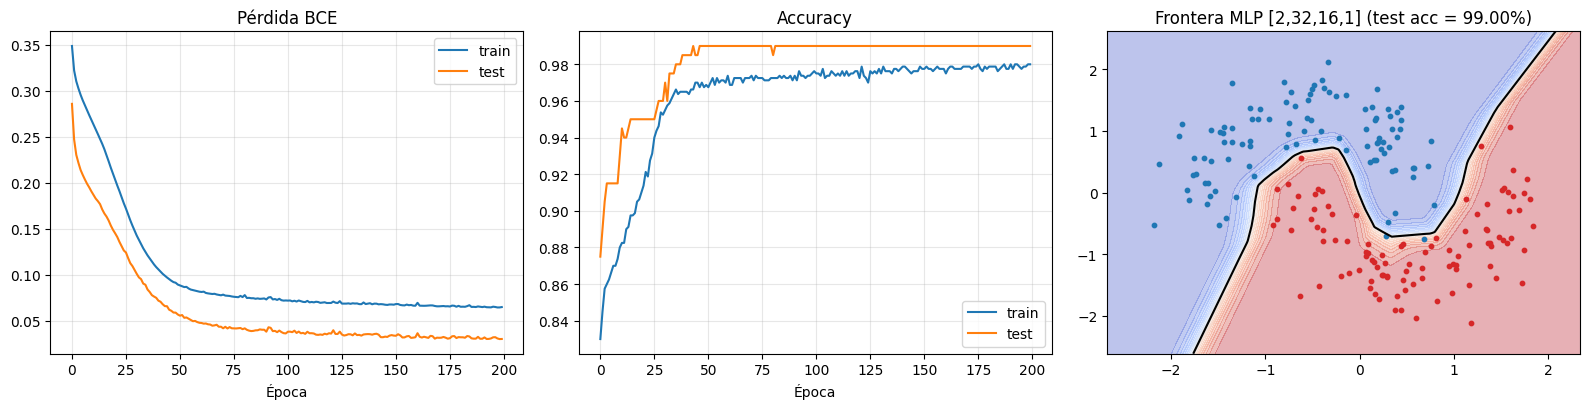

In [6]:
fig, axes = plt.subplots(1, 3, figsize=(16, 4.2))
h = mlp_moons.historial
axes[0].plot(h["loss"], label="train"); axes[0].plot(h["val_loss"], label="test")
axes[0].set_title("Pérdida BCE"); axes[0].set_xlabel("Época"); axes[0].legend(); axes[0].grid(alpha=.3)
axes[1].plot(h["acc"], label="train"); axes[1].plot(h["val_acc"], label="test")
axes[1].set_title("Accuracy"); axes[1].set_xlabel("Época"); axes[1].legend(); axes[1].grid(alpha=.3)
xx, yy = np.meshgrid(np.linspace(Xte[:, 0].min() - .5, Xte[:, 0].max() + .5, 300),
                     np.linspace(Xte[:, 1].min() - .5, Xte[:, 1].max() + .5, 300))
zz = mlp_moons.predict_proba(np.c_[xx.ravel(), yy.ravel()]).reshape(xx.shape)
axes[2].contourf(xx, yy, zz, levels=20, cmap="coolwarm", alpha=.35)
axes[2].contour(xx, yy, zz, levels=[0.5], colors="k")
axes[2].scatter(Xte[yte == 0, 0], Xte[yte == 0, 1], s=10, c="tab:blue")
axes[2].scatter(Xte[yte == 1, 0], Xte[yte == 1, 1], s=10, c="tab:red")
axes[2].set_title(f"Frontera MLP [2,32,16,1] (test acc = {acc_moons:.2%})")
plt.tight_layout(); plt.savefig(f"{FIG_DIR}/03_mlp_moons.png", dpi=150); plt.show()

## 5. Experimento B — dataset real: Breast Cancer Wisconsin (diagnóstico)

569 tumores descritos por 30 características numéricas (radio, textura, concavidad, etc.).
Etiqueta: 0 = maligno, 1 = benigno. Solo cambia la **primera** capa de la arquitectura (30 entradas):
el resto del código es idéntico, lo que demuestra que el modelo es reutilizable.

In [7]:
datos = load_breast_cancer()
Xb, yb = datos.data, datos.target
Xb_tr, Xb_te, yb_tr, yb_te = train_test_split(Xb, yb, test_size=0.20, random_state=SEED, stratify=yb)
sc_b = StandardScaler().fit(Xb_tr)
Xb_tr, Xb_te = sc_b.transform(Xb_tr), sc_b.transform(Xb_te)
print("Train:", Xb_tr.shape, "| Test:", Xb_te.shape, "| Clases (train):", np.bincount(yb_tr))

mlp_bc = MLP([30, 16, 8, 1], lr=0.01)
mlp_bc.fit(Xb_tr, yb_tr, Xb_te, yb_te, epochs=100, batch_size=32, verbose=20)

yb_pred = mlp_bc.predict(Xb_te)
print(f"\nMLP Breast Cancer -> accuracy en test: {np.mean(yb_pred == yb_te):.4f}\n")
print(classification_report(yb_te, yb_pred, target_names=datos.target_names, digits=4))

Train: (455, 30) | Test: (114, 30) | Clases (train): [170 285]
época   20 | loss 0.1425 | acc 0.9758 | val_loss 0.1600 | val_acc 0.9561
época   40 | loss 0.0832 | acc 0.9846 | val_loss 0.1169 | val_acc 0.9474
época   60 | loss 0.0643 | acc 0.9846 | val_loss 0.1030 | val_acc 0.9561
época   80 | loss 0.0549 | acc 0.9868 | val_loss 0.0967 | val_acc 0.9561
época  100 | loss 0.0490 | acc 0.9868 | val_loss 0.0927 | val_acc 0.9561

MLP Breast Cancer -> accuracy en test: 0.9561

              precision    recall  f1-score   support

   malignant     0.9302    0.9524    0.9412        42
      benign     0.9718    0.9583    0.9650        72

    accuracy                         0.9561       114
   macro avg     0.9510    0.9554    0.9531       114
weighted avg     0.9565    0.9561    0.9562       114



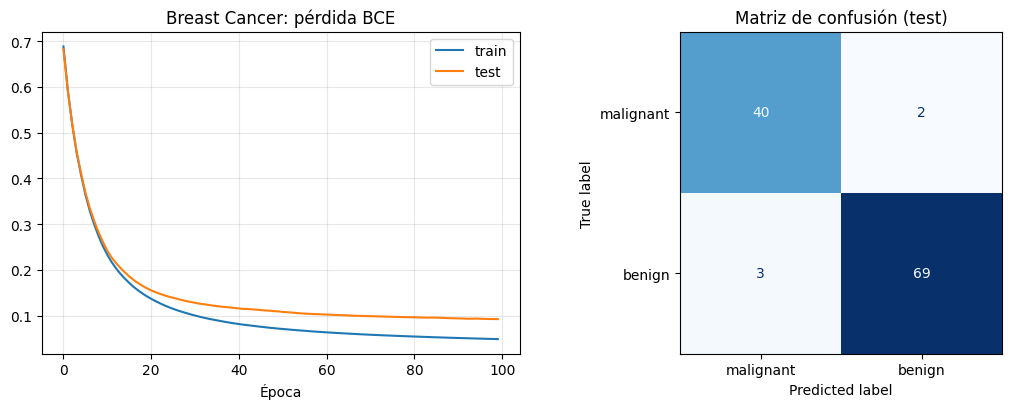

In [8]:
fig, axes = plt.subplots(1, 2, figsize=(11, 4.2))
h = mlp_bc.historial
axes[0].plot(h["loss"], label="train"); axes[0].plot(h["val_loss"], label="test")
axes[0].set_title("Breast Cancer: pérdida BCE"); axes[0].set_xlabel("Época"); axes[0].legend(); axes[0].grid(alpha=.3)
ConfusionMatrixDisplay(confusion_matrix(yb_te, yb_pred), display_labels=datos.target_names).plot(
    ax=axes[1], cmap="Blues", colorbar=False)
axes[1].set_title("Matriz de confusión (test)")
plt.tight_layout(); plt.savefig(f"{FIG_DIR}/03_mlp_breast_cancer.png", dpi=150); plt.show()

## 6. Análisis

- El *gradient checking* valida matemáticamente la implementación de backpropagation.
- En `make_moons` el MLP aprende una frontera no lineal ajustada a la forma de las lunas.
- En Breast Cancer el mismo código, cambiando solo la arquitectura, alcanza una exactitud alta en test.
  En un contexto médico importa especialmente el **recall de la clase maligna** (falsos negativos), que se
  lee en el reporte de clasificación y en la matriz de confusión.
- Esta estructura (capas con `forward`/`backward`, pérdida, optimizador y bucle de entrenamiento) es la misma
  que automatizan TensorFlow/Keras (`model.fit`) y PyTorch (`loss.backward()` + `optimizer.step()`).

In [10]:
!zip -r resultados.zip figuras
from google.colab import files
files.download("resultados.zip")

updating: figuras/ (stored 0%)
updating: figuras/03_mlp_moons.png (deflated 7%)
updating: figuras/03_mlp_breast_cancer.png (deflated 12%)


<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>